# 02 — Customer Analysis

Repeat-customer behaviour and RFM (recency, frequency, monetary) segmentation of the Olist marketplace. A customer is identified by `customer_unique_id`. Monetary values are in BRL (R$).

## Data Setup

In [104]:
# Connect to the local ecommerce database
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg://localhost/ecommerce")

In [105]:
# Shared chart style: dark theme and font for every chart in this notebook
import matplotlib.pyplot as plt

# Colour constants: change a colour here and every chart follows
BG = "#1a1a19"          # background
TEXT = "#f0efec"        # titles and key labels
TEXT_MUTED = "#c3c2b7"  # axis labels, ticks and annotations
BLUE = "#3987e5"        # main series
ORANGE = "#d95926"      # highlight

# rcParams holds matplotlib's global settings
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "text.color": TEXT,
    "axes.labelcolor": TEXT_MUTED,
    "axes.edgecolor": TEXT_MUTED,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "grid.color": "#383835",
    "font.family": ["Avenir Next", "Helvetica Neue", "DejaVu Sans"],  # first installed font is used
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## Repeat Customers

How many customers come back, and how long do they take?

Grain: one row per order. `customer_id` changes with every order; `customer_unique_id` is the person.

In [106]:
# One row per order, with the underlying customer
customer_orders_query = """
SELECT
    customers.customer_unique_id,
    orders.order_id,
    orders.order_purchase_timestamp
FROM orders
JOIN customers
    ON orders.customer_id = customers.customer_id
"""

customer_orders = pd.read_sql(customer_orders_query, engine)

In [107]:
# Number each customer's orders in time order: 1 = first order, 2 = second, ...
customer_orders = customer_orders.sort_values(["customer_unique_id", "order_purchase_timestamp"])
customer_orders["order_number"] = customer_orders.groupby("customer_unique_id").cumcount() + 1

# Orders per customer, and how many customers ordered more than once
orders_per_customer = customer_orders.groupby("customer_unique_id").size()
repeat_rate = (orders_per_customer >= 2).mean()
print(f"{(orders_per_customer >= 2).sum()} of {len(orders_per_customer)} customers ordered more than once ({repeat_rate:.2%})")

2997 of 96096 customers ordered more than once (3.12%)


In [108]:
# First and second order of each repeat customer, side by side
first = customer_orders[customer_orders["order_number"] == 1]
second = customer_orders[customer_orders["order_number"] == 2]
both = first.merge(second, on="customer_unique_id", suffixes=("_first", "_second"))

# Days between the first and second order
both["days_to_second"] = (both["order_purchase_timestamp_second"] - both["order_purchase_timestamp_first"]
                          ).dt.total_seconds() / 86400
both["days_to_second"].describe()

count    2997.000000
mean       80.349981
std       110.192404
min         0.000000
25%         0.001400
50%        27.923773
75%       123.111019
max       608.978912
Name: days_to_second, dtype: float64

**Why we don't just report 3.12%**

The `min` and `25%` rows above show that at least a quarter of "repeat" customers placed their second order within about two minutes of the first (0.0014 days). That isn't a customer coming back. It looks like one purchase split into two orders.

So we use two definitions:

- **2+ orders (3.12%):** the simple count. It includes split orders, so it overstates real repeat buying.
- **Returning (about 2.2%):** a second order at least one day after the first. This is the headline figure.

The buckets below show how many customers fall on each side of that line.

days_to_second
within 1 day     30.9
2-30 days        20.1
31-90 days       17.6
91-180 days      14.1
181-365 days     14.2
over 365 days     2.9
Name: proportion, dtype: float64
2070 of 96096 customers (2.15%) came back at least a day later


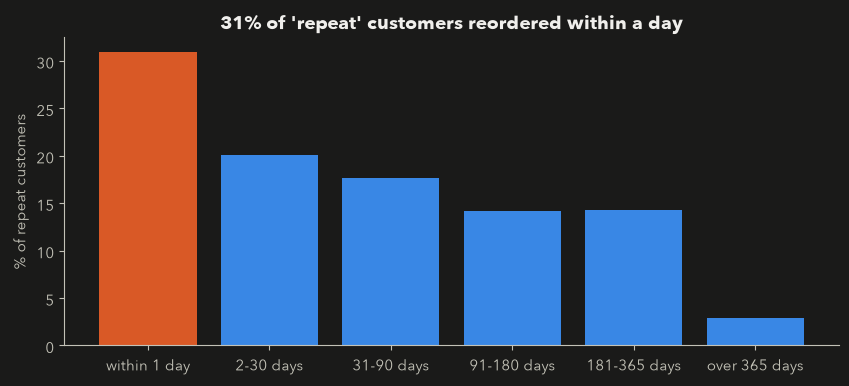

In [109]:
# Share of repeat customers by time to second order
buckets = pd.cut(
    both["days_to_second"],
    bins=[-0.001, 1, 30, 90, 180, 365, float("inf")],
    labels=["within 1 day", "2-30 days", "31-90 days", "91-180 days", "181-365 days", "over 365 days"],
)
bucket_share = buckets.value_counts(normalize=True, sort=False) * 100
print(bucket_share.round(1))

# Customers who came back at least a day after their first order, as a share of all customers
returning = (both["days_to_second"] >= 1).sum()
print(f"{returning} of {len(orders_per_customer)} customers ({returning / len(orders_per_customer):.2%}) came back at least a day later")

fig, ax = plt.subplots(figsize=(10, 4))
colors = [ORANGE] + [BLUE] * (len(bucket_share) - 1)  # highlight the first bucket
ax.bar(bucket_share.index, bucket_share.values, color=colors)
ax.set_ylabel("% of repeat customers")
ax.set_title(f"{bucket_share.iloc[0]:.0f}% of 'repeat' customers reordered within a day")
plt.show()

**Finding**

- **2.2% of customers returned** (2,070 of 96,096), not the 3.1% a simple 2+ orders count suggests.
- **31% of "repeat" customers reordered within a day**, often within minutes: likely split orders, not return visits.
- **The other 69% return across the year:** 20% within 2-30 days, 18% in 31-90, 14% each in 91-180 and 181-365, 3% later.
- **About 98% never came back**, so growth depends on new customers.

## Customer Value

Are returning customers worth more than one-time customers?

An RFM table (recency, frequency, monetary) gives each customer's key numbers. Almost all customers buy once, so frequency barely varies; instead of scoring segments, we compare returning and one-time customers directly.

- **Recency:** days since the customer's last order
- **Frequency:** number of purchase days (split orders on the same day count once)
- **Monetary:** total customer payment value (R$)

Grain: one row per customer (`customer_unique_id`).

In [110]:
# Total customer payment per order (an order can have several payment rows)
order_payments_query = """
SELECT
    order_id,
    SUM(payment_value) AS payment_value
FROM order_payments
GROUP BY order_id
"""

order_payments_totals = pd.read_sql(order_payments_query, engine)
order_payments_totals.shape  # one row per order that has a payment

(99440, 2)

In [111]:
# Add each order's payment value (left join keeps the order that has no payment)
customer_orders = customer_orders.merge(order_payments_totals, on="order_id", how="left")
customer_orders["payment_value"] = customer_orders["payment_value"].fillna(0)

# Purchase day: orders placed on the same day count as one purchase
customer_orders["purchase_date"] = customer_orders["order_purchase_timestamp"].dt.date

# Snapshot date: the day after the last order in the data; recency is measured from here
snapshot_date = customer_orders["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)

# One row per customer: last order, number of purchase days, total spend
rfm = customer_orders.groupby("customer_unique_id").agg(
    last_order=("order_purchase_timestamp", "max"),
    frequency=("purchase_date", "nunique"),
    monetary=("payment_value", "sum"),
)
rfm["recency"] = (snapshot_date - rfm["last_order"]).dt.days
rfm[["recency", "frequency", "monetary"]].describe().round(1)

,recency,frequency,monetary
count,96096.0,96096.0,96096.0
mean,288.1,1.0,166.6
std,153.4,0.2,231.4
min,0.0,1.0,0.0
25%,164.0,1.0,63.1
50%,269.0,1.0,108.0
75%,397.0,1.0,183.5
max,773.0,17.0,13664.1


In [112]:
# Returning (2+ purchase days) vs one-time customers: how many, spend per customer, share of revenue
rfm["customer_type"] = (rfm["frequency"] >= 2).map({True: "Returning", False: "One-time"})

value = rfm.groupby("customer_type").agg(
    customers=("monetary", "count"),
    avg_spend=("monetary", "mean"),
    total_spend=("monetary", "sum"),
)
value["customer_share_pct"] = value["customers"] / value["customers"].sum() * 100
value["revenue_share_pct"] = value["total_spend"] / value["total_spend"].sum() * 100
print(value.round(1))

               customers  avg_spend  total_spend  customer_share_pct  \
customer_type                                                          
One-time           93947      162.9   15301860.3                97.8   
Returning           2149      329.0     707011.8                 2.2   

               revenue_share_pct  
customer_type                     
One-time                    95.6  
Returning                    4.4  


**Finding**

- **Returning customers are rare but worth more each:** 2,149 customers (2.2%) bought on 2+ days and spent R$329 on average, about double the R$163 of one-time customers (R$ payment value).
- **They bring only 4.4% of revenue** (R$0.7M of R$16.0M), so the marketplace lives on first-time buyers.
- **Caveat:** 2,149 counts calendar days, so it differs slightly from the 2,070 at least a day apart; both round to 2.2%.